=== RINGKASAN HASIL PERHITUNGAN PYTHON SLP ===
  Epoch  Training Loss (MSE)  Validation Loss (MSE)  Training Accuracy (%)  Validation Accuracy (%)
Epoch 1             0.290514               0.304885                  68.75                     50.0
Epoch 2             0.032277               0.226122                  95.00                     50.0
Epoch 3             0.021663               0.157328                  97.50                     50.0
Epoch 4             0.015514               0.106769                  97.50                     85.0
Epoch 5             0.011513               0.072541                  98.75                    100.0


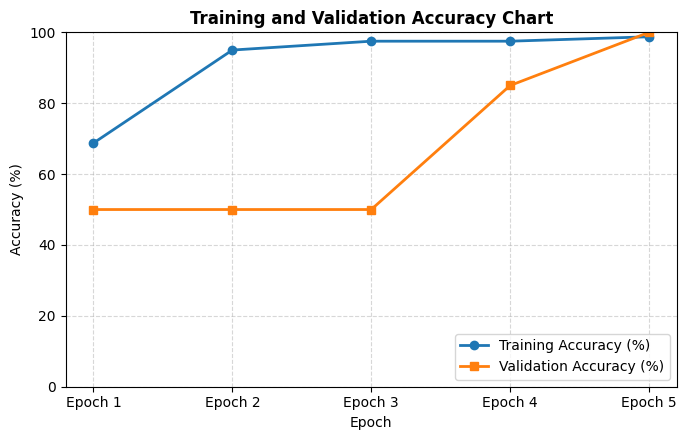

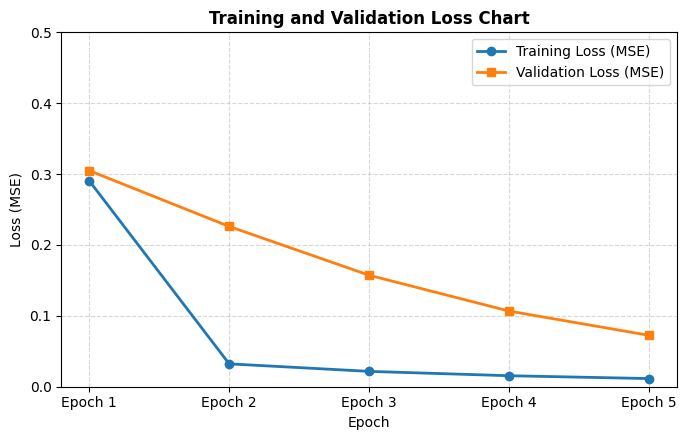

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. DEFINISI FUNGSI & PARAMETER SLP
# ==========================================
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

# Parameter sesuai lembar kerja Excel
learning_rate = 0.1
epochs = 5

# Inisialisasi bobot dan bias awal (sesuai baris 5 sheet SLP-Training)
bias = 0.0
weights = np.array([0.5, 0.5, 0.5, 0.5])

# ==========================================
# 2. MEMUAT DATASET (SESUAI GOOGLE SHEETS)
# ==========================================
excel_file = 'PMM-TemplateSLP.xlsx'

# Membaca 80 Data Training (Baris 5 s.d. 84)
df_train = pd.read_excel(excel_file, sheet_name='SLP-Training', skiprows=3, nrows=80)
X_train = df_train.iloc[:, 2:6].values   # Kolom X1, X2, X3, X4
y_train = df_train.iloc[:, 6].values     # Kolom TARGET (0 / 1)

# Membaca 20 Data Validation (Baris 7 s.d. 26)
df_val = pd.read_excel(excel_file, sheet_name='SLP-Validation', skiprows=5, nrows=20)
X_val = df_val.iloc[:, 2:6].values       # Kolom X1, X2, X3, X4
y_val = df_val.iloc[:, 6].values         # Kolom TARGET (0 / 1)

# List untuk menyimpan histori evaluasi
history_tr_loss, history_tr_acc = [], []
history_val_loss, history_val_acc = [], []

# ==========================================
# 3. PROSES PELATIHAN & VALIDASI (EPOCH 1-5)
# ==========================================
for epoch in range(1, epochs + 1):
    sse_tr = 0.0
    correct_tr = 0

    # --- PROSES TRAINING (Gradient Descent Kontinyu) ---
    for i in range(len(X_train)):
        xi = X_train[i]
        yi = y_train[i]

        # Feedforward
        z = bias + np.dot(weights, xi)
        gz = sigmoid(z)
        pred = 1 if gz > 0.5 else 0

        # Hitung Error & SSE
        err = gz - yi
        sse_tr += err ** 2
        if pred == yi:
            correct_tr += 1

        # Hitung Gradien Turunan (Sesuai Rumus Excel: dbias & dteta)
        dbias = 2.0 * (gz - yi) * (1.0 - gz) * gz
        dweights = dbias * xi

        # Update Bobot & Bias secara kontinyu
        bias -= learning_rate * dbias
        weights -= learning_rate * dweights

    # Catat performa Training Epoch ini
    tr_loss = sse_tr / len(X_train)
    tr_acc = (correct_tr / len(X_train)) * 100
    history_tr_loss.append(tr_loss)
    history_tr_acc.append(tr_acc)

    # --- PROSES VALIDATION (Bobot Konstan Di-lock dari Akhir Training) ---
    sse_val = 0.0
    correct_val = 0
    for i in range(len(X_val)):
        xi = X_val[i]
        yi = y_val[i]

        z = bias + np.dot(weights, xi)
        gz = sigmoid(z)
        pred = 1 if gz > 0.5 else 0

        err = gz - yi
        sse_val += err ** 2
        if pred == yi:
            correct_val += 1

    # Catat performa Validation Epoch ini
    val_loss = sse_val / len(X_val)
    val_acc = (correct_val / len(X_val)) * 100
    history_val_loss.append(val_loss)
    history_val_acc.append(val_acc)

# Menampilkan tabel ringkasan hasil kalkulasi Python
epochs_label = [f'Epoch {i}' for i in range(1, 6)]
df_result = pd.DataFrame({
    'Epoch': epochs_label,
    'Training Loss (MSE)': history_tr_loss,
    'Validation Loss (MSE)': history_val_loss,
    'Training Accuracy (%)': history_tr_acc,
    'Validation Accuracy (%)': history_val_acc
})
print("=== RINGKASAN HASIL PERHITUNGAN PYTHON SLP ===")
print(df_result.to_string(index=False))

# ====================
# 4. MEMBUAT GRAFIK
# ====================

# GRAFIK 1: Accuracy Chart (Page 3 PPT)
plt.figure(figsize=(7, 4.5))
plt.plot(epochs_label, history_tr_acc, marker='o', color='#1f77b4', linewidth=2, label='Training Accuracy (%)')
plt.plot(epochs_label, history_val_acc, marker='s', color='#ff7f0e', linewidth=2, label='Validation Accuracy (%)')
plt.title('Training and Validation Accuracy Chart', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('page3_accuracy_chart_python.png')
plt.show()

# GRAFIK 2: Loss Chart (Page 5 PPT)
plt.figure(figsize=(7, 4.5))
plt.plot(epochs_label, history_tr_loss, marker='o', color='#1f77b4', linewidth=2, label='Training Loss (MSE)')
plt.plot(epochs_label, history_val_loss, marker='s', color='#ff7f0e', linewidth=2, label='Validation Loss (MSE)')
plt.title('Training and Validation Loss Chart', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.ylim(0, 0.5)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig('page5_loss_chart_python.png')
plt.show()